# 14. RL Formulation and Pilot

This notebook defines the first Study 3 Q-Learning setup, checks reward scales, and runs a small pilot before expanding to more seeds.

## Reference setup

- Four Census regions; one independent tabular Q-Learning agent per region.
- Annual steps; 40-year episodes. Episodes end at the configured horizon. There are no pollution-based terminal failures.
- Reference economics: 60% income retention and constant development cost of 25 currency units per EDI point.
- Sensitivity runs: 40% and 80% retention, and quadratic development costs.
- Pollution remains continuous in the environment and is reported in the modeled units.

In [1]:
import json
import pandas as pd
import matplotlib.pyplot as plt

from study_3_pollutant_dynamics.config import EnvironmentConfig
from study_3_pollutant_dynamics.integrated_environment import Study3IntegratedEnvironment
from study_3_pollutant_dynamics.policy_evaluation import (FIXED_POLICY_NAMES, choose_fixed_policy_actions,
                                                          summarize_integrated_episode, evaluate_fixed_policies)
from study_3_pollutant_dynamics.rl_formulation import (ACTION_NAMES, STATE_BIN_EDGES, POLLUTION_WEIGHT,
                                                       build_no_action_reference, calculate_reward_components,
                                                       decode_actions, encode_observation, make_reward_function, rewards_for_mode)
from study_3_pollutant_dynamics.scenario_parameters import get_parameters
from study_3_pollutant_dynamics.train import run_agent_episode, save_policy_q_tables, train_agents

In [2]:
REFERENCE_RETENTION = 0.6
REFERENCE_COST_SHAPE = "constant"
STARTING_CURRENCY_MULTIPLIER = 1.0
EPISODE_YEARS = 40
TRAINING_SEEDS = [11, 23, 37]
REWARD_MODES = ["local", "global", "mixed"]
FIXED_POLICIES = list(FIXED_POLICY_NAMES)
PILOT_EPISODES = 100
FULL_TRAINING_EPISODES = 300
LEARNING_RATE = 0.2
DISCOUNT_FACTOR = 0.95
EPSILON_START = 1.0
EPSILON_DECAY = 0.99
EPSILON_MINIMUM = 0.05

reference_config = EnvironmentConfig(get_parameters(episode_steps=EPISODE_YEARS))
reference_environment = Study3IntegratedEnvironment(reference_config, starting_currency_multiplier=STARTING_CURRENCY_MULTIPLIER,
                                                    development_cost_shape=REFERENCE_COST_SHAPE,
                                                    income_retention_fraction=REFERENCE_RETENTION)
number_of_regions = len(reference_config.regions)
state_dimension_rows = []
state_count = 1
for feature_name, boundaries in STATE_BIN_EDGES.items():
    number_of_bins = len(boundaries) + 1
    state_count *= number_of_bins
    state_dimension_rows.append({"feature": feature_name, "bins": number_of_bins})

display(pd.DataFrame(state_dimension_rows))
print("Possible local states:", state_count)
print("Actions per agent:", len(ACTION_NAMES))
print("Joint actions across four independent agents:", len(ACTION_NAMES) ** number_of_regions)
print("Dense Q values per agent:", state_count * len(ACTION_NAMES))


,feature,bins
0,EDI,7
1,currency,6
2,PM2.5_ug_m3,3
3,CO2_ppm,4
4,Nitrate-N_mg_L,3
5,Lead_total_kg,3
6,Lead_mobile_kg,3
7,year,4


Possible local states: 54432
Actions per agent: 8
Joint actions across four independent agents: 4096
Dense Q values per agent: 435456


## Observation and action spaces

Each region observes its own PM2.5 exposure, nitrate concentration, total and mobile lead, EDI, currency, the shared CO2 concentration, and the year. The environment also reports nitrate stock and region index; the encoder drops nitrate stock because concentration is calculated from that stock, and drops region index because each region has its own Q-table.

The encoder uses eight integer bins: EDI, currency, PM2.5, CO2, nitrate-N, total lead, mobile lead, and episode year. The resulting 54,432 possible states per agent are stored sparsely. The model equations and continuous state values are unchanged.

Each agent chooses one of eight existing actions: maintain, develop, prevention, develop with prevention, cleanup, develop with cleanup, balanced investment, or develop with balanced investment. The four agents choose independently, so no joint action table is stored.

The local observation does not include the full age of each mitigation project or every lagged income and damage variable. This is a compact local-observation baseline, so state aggregation and partial observability may limit Q-Learning.

## Reward equations

For region `i` in year `t`, let `dEDI` be its EDI change. Let `P[i,t]` be the average of four pollutant differences from the matched no-development/no-investment reference path, each divided by a scale:

- PM2.5 difference / 9 micrograms per cubic meter.
- CO2 difference / 100 ppm.
- Nitrate-N difference / 10 mg N/L.
- Mobile lead difference / that region's initial mobile lead stock.

`P` is dimensionless. A positive value means pollution is above the reference path; a negative value means it is lower. The local reward is `r[i] = dEDI - 1.0 * P[i,t]`. Global reward is the mean of the four local rewards. Mixed reward is `0.7 * local + 0.3 * global`, matching the Study 2 split.

Income and development or mitigation spending are logged but do not receive separate reward terms. Income already changes available currency; spending already reduces it. A direct income bonus or spending penalty would count those budget effects again. Pollution damage also changes income, so damage fraction is logged rather than separately penalized.

## Guideline comparisons

Guideline comparisons are reported separately from the reward and do not end episodes:

- PM2.5: compare annual exposure with EPA's 9 micrograms per cubic meter annual primary standard. The formal standard uses a three-year average, so the annual model comparison is a screening indicator. [EPA NAAQS table](https://www.epa.gov/criteria-air-pollutants/naaqs-table)
- Nitrate-N: compare concentration with the 10 mg/L drinking-water MCL. The modeled catchment is not a treated public water system. [EPA drinking-water regulations](https://www.epa.gov/ground-water-and-drinking-water/national-primary-drinking-water-regulations)
- Lead: compare total soil concentration with EPA's 200 mg/kg residential soil screening level. The modeled parcel is not a site-specific residential assessment. [EPA residential soil lead guidance](https://www.epa.gov/superfund/residential-soil-lead-directive-cercla-sites-and-rcra-hazardous-waste-cleanup-facilities)
- CO2: report atmospheric ppm; there is no ambient CO2 concentration threshold in this comparison.

In [3]:
reference_states = build_no_action_reference(reference_config, STARTING_CURRENCY_MULTIPLIER, REFERENCE_RETENTION)
print("Reference trajectory years:", len(reference_states) - 1)
print("Reference start CO2:", round(reference_states[0][0]["CO2_ppm"], 3), "ppm")
print("Reference end CO2:", round(reference_states[-1][0]["CO2_ppm"], 3), "ppm")

Reference trajectory years: 40
Reference start CO2: 425.62 ppm
Reference end CO2: 525.62 ppm


In [4]:
def evaluate_fixed_policy_reward(policy_name):
    environment = Study3IntegratedEnvironment(reference_config, starting_currency_multiplier=STARTING_CURRENCY_MULTIPLIER,
                                              development_cost_shape=REFERENCE_COST_SHAPE,
                                              income_retention_fraction=REFERENCE_RETENTION)
    observations = environment.reset(0)
    trajectory = []
    component_totals = {"development_reward": 0.0, "pollution_reward": 0.0, "pollution_pressure": 0.0,
                        "gross_income": 0.0, "net_income": 0.0, "development_spending": 0.0,
                        "mitigation_spending": 0.0}
    regional_component_totals = []
    for region in range(number_of_regions):
        regional_component_totals.append({"development_reward": 0.0, "pollution_reward": 0.0,
                                          "pollution_pressure": 0.0})
    edi_total = 0.0
    edi_count = 0

    while not environment.done:
        actions = choose_fixed_policy_actions(policy_name, environment)
        next_observations, terminated, truncated, info = environment.step(actions)
        reward_components = calculate_reward_components(observations, next_observations, info, reference_states)

        for region, row in enumerate(reward_components["regional_components"]):
            for name in ("development_reward", "pollution_reward", "pollution_pressure"):
                regional_component_totals[region][name] += row[name]
                component_totals[name] += row[name]

            component_totals["gross_income"] += info["regional_economy"][region]["gross_income"]
            component_totals["net_income"] += row["net_income"]
            component_totals["development_spending"] += row["development_spending"]
            component_totals["mitigation_spending"] += row["mitigation_spending"]
            edi_total += next_observations[region]["EDI"]
            edi_count += 1
        trajectory.append(info)
        observations = next_observations

    summary = summarize_integrated_episode(policy_name, trajectory, environment)
    summary.update(component_totals)
    summary["average_EDI"] = edi_total / edi_count
    summary["regional_reward_totals"] = regional_component_totals
    return summary, trajectory, environment

In [5]:
fixed_results = []
fixed_trajectories = {}
fixed_environments = {}

for policy_name in FIXED_POLICIES:
    summary, trajectory, environment = evaluate_fixed_policy_reward(policy_name)
    fixed_results.append(summary)
    fixed_trajectories[policy_name] = trajectory
    fixed_environments[policy_name] = environment

fixed_summary = pd.DataFrame(fixed_results)
fixed_columns = ["policy", "development_reward", "pollution_reward", "final_mean_EDI", "average_EDI",
                 "final_mean_currency", "gross_income", "net_income", "development_spending",
                 "mitigation_spending", "final_CO2_ppm", "final_mean_PM2.5_ug_m3",
                 "final_mean_nitrate_mg_N_L", "final_mean_lead_total_kg"]
display(fixed_summary[fixed_columns].round(3))

,policy,development_reward,pollution_reward,final_mean_EDI,average_EDI,final_mean_currency,gross_income,net_income,development_spending,mitigation_spending,final_CO2_ppm,final_mean_PM2.5_ug_m3,final_mean_nitrate_mg_N_L,final_mean_lead_total_kg
0,no_development_no_investment,0.0,0.000,65.00,65.000,2962.355,15896.854,15582.365,0.0,0.0,525.620,8.563,2.258,16.215
1,development_only,135.0,-3.833,98.75,84.406,2159.204,16849.575,15853.030,3375.0,0.0,529.662,8.614,3.209,17.123
2,prevention_focused,135.0,0.950,98.75,84.406,1740.733,17755.708,17329.887,3375.0,2560.0,526.749,8.570,2.568,15.921
3,cleanup_focused,135.0,2.813,98.75,84.406,1505.338,17709.473,16827.252,3375.0,3200.0,529.523,8.614,3.087,12.908
4,balanced,135.0,34.605,98.75,84.406,913.742,18526.238,18216.615,3375.0,6400.0,526.610,8.570,2.445,11.707


In [6]:
def guideline_exceedance_summary(trajectory, config, policy_name):
    pm25_exceedances = 0
    nitrate_exceedances = 0
    lead_exceedances = 0
    region_years = len(trajectory) * len(config.regions)

    for info in trajectory:
        for region in range(len(config.regions)):
            if info["stocks"]["PM2.5"][region] > 9.0:
                pm25_exceedances += 1
            nitrate_mg_l = 1000 * info["stocks"]["Nitrate-N"][region] / config.nitrate["water_volume_m3"]
            if nitrate_mg_l > 10.0:
                nitrate_exceedances += 1
            lead_mg_kg = info["stocks"]["Lead"][region] / config.lead["soil_mass_kg"] * 1e6
            if lead_mg_kg > 200.0:
                lead_exceedances += 1

    return {"policy": policy_name, "region_years": region_years, "PM2.5_years_above_9": pm25_exceedances,
            "nitrate_years_above_10": nitrate_exceedances, "lead_years_above_200": lead_exceedances}

In [7]:
guideline_rows = []
for policy_name in FIXED_POLICIES:
    guideline_rows.append(guideline_exceedance_summary(fixed_trajectories[policy_name], reference_config, policy_name))
display(pd.DataFrame(guideline_rows))

,policy,region_years,PM2.5_years_above_9,nitrate_years_above_10,lead_years_above_200
0,no_development_no_investment,160,40,0,0
1,development_only,160,40,0,0
2,prevention_focused,160,40,0,0
3,cleanup_focused,160,40,0,0
4,balanced,160,40,0,0


## Pilot settings

The first pilot uses 100 episodes per reward mode and one training seed. Q-Learning uses epsilon-greedy action selection, a 0.2 starting learning rate that decays as `0.2 / sqrt(state-action visits)`, and a 0.95 discount factor. Epsilon starts at 1.0, decays by 0.99 per episode, and stops at 0.05.

The greedy evaluation uses the same 40-year reference start as the fixed policies. The pilot checks code execution, table updates, action coverage, and whether rewards change during training. It is not a hyperparameter search.

In [8]:
PILOT_SEED = 11
pilot_agents = {}
pilot_training_rows = []
pilot_evaluation_rows = []
pilot_evaluation_trajectories = {}
pilot_action_rows = []

for reward_mode in REWARD_MODES:
    environment = Study3IntegratedEnvironment(reference_config, starting_currency_multiplier=STARTING_CURRENCY_MULTIPLIER,
                                              development_cost_shape=REFERENCE_COST_SHAPE,
                                              income_retention_fraction=REFERENCE_RETENTION)

    reward_function = make_reward_function(reward_mode, reference_states)
    agents, episode_rows = train_agents(environment, len(ACTION_NAMES), PILOT_SEED, PILOT_EPISODES,
                                        encode_observation, decode_actions, reward_function,
                                        LEARNING_RATE, DISCOUNT_FACTOR, EPSILON_START, EPSILON_DECAY, EPSILON_MINIMUM)
    pilot_agents[reward_mode] = agents
    for row in episode_rows:
        row["reward_mode"] = reward_mode
        pilot_training_rows.append(row)

    evaluation_environment = Study3IntegratedEnvironment(reference_config, starting_currency_multiplier=STARTING_CURRENCY_MULTIPLIER,
                                                          development_cost_shape=REFERENCE_COST_SHAPE,
                                                          income_retention_fraction=REFERENCE_RETENTION)
    evaluation_rewards, evaluation_trajectory, action_counts = run_agent_episode(evaluation_environment, agents, 0, encode_observation,
                                                                                 decode_actions, reward_function)

    evaluation_summary = summarize_integrated_episode("independent_q_learning", evaluation_trajectory, evaluation_environment)
    evaluation_summary["reward_mode"] = reward_mode
    evaluation_summary["training_seed"] = PILOT_SEED
    evaluation_summary["cumulative_reward"] = sum(evaluation_rewards)
    evaluation_summary["visited_states"] = sum(len(agent.q_values) for agent in agents)
    pilot_evaluation_rows.append(evaluation_summary)
    pilot_evaluation_trajectories[reward_mode] = evaluation_trajectory

    for region, counts in enumerate(action_counts):
        for action_name, count in counts.items():
            pilot_action_rows.append({"reward_mode": reward_mode, "region": reference_config.regions[region],
                                      "action": action_name, "count": count})

pilot_training = pd.DataFrame(pilot_training_rows)
pilot_evaluation = pd.DataFrame(pilot_evaluation_rows)
pilot_actions = pd.DataFrame(pilot_action_rows)
display(pilot_evaluation[["reward_mode", "cumulative_reward", "final_mean_EDI", "final_mean_currency",
                          "investment_package_purchases", "visited_states"]].round(3))

,reward_mode,cumulative_reward,final_mean_EDI,final_mean_currency,investment_package_purchases,visited_states
0,local,139.247,96.0,1556.317,26,171
1,global,124.712,92.5,1726.838,22,159
2,mixed,137.793,95.5,1574.899,27,169


In [9]:
pilot_training_summary_rows = []
for reward_mode in REWARD_MODES:
    reward_rows = pilot_training[pilot_training["reward_mode"] == reward_mode]
    first_20_mean = reward_rows.head(20)["mean_cumulative_reward_per_region"].mean()
    last_20_mean = reward_rows.tail(20)["mean_cumulative_reward_per_region"].mean()
    average_episode_reward = reward_rows["mean_cumulative_reward_per_region"].mean()

    pilot_training_summary_rows.append({"reward_mode": reward_mode, "first_20_mean_cumulative_reward_per_region": first_20_mean,
                                        "last_20_mean_cumulative_reward_per_region": last_20_mean,
                                        "average_episode_reward": average_episode_reward})

pilot_training_summary = pd.DataFrame(pilot_training_summary_rows)
display(pilot_training_summary.round(3))
display(pilot_actions.pivot_table(index=["reward_mode", "region"], columns="action", values="count", fill_value=0))

,reward_mode,first_20_mean_cumulative_reward_per_region,last_20_mean_cumulative_reward_per_region,average_episode_reward
0,local,25.760,33.394,29.975
1,global,25.702,31.650,29.033
2,mixed,25.767,33.146,29.919


action                 balanced  cleanup  develop  develop_balanced  \
reward_mode region                                                    
global      Midwest         7.0      0.0     10.0              17.0   
            Northeast       0.0      0.0      4.0              11.0   
            South           0.0      2.0     14.0               0.0   
            West            0.0      0.0      5.0              11.0   
local       Midwest         0.0      0.0      1.0              11.0   
            Northeast       0.0      0.0      3.0              15.0   
            South           0.0      0.0     15.0              10.0   
            West            0.0      1.0     19.0               3.0   
mixed       Midwest         0.0      0.0      0.0              18.0   
            Northeast       0.0      0.0      3.0              15.0   
            South           0.0      0.0     10.0               5.0   
            West            0.0      0.0     18.0               3.0   

action                 develop_cleanup  develop_prevention  maintain  \
reward_mode region                                                     
global      Midwest                3.0                 0.0       2.0   
            Northeast             13.0                 3.0       9.0   
            South                  3.0                 8.0      13.0   
            West                  14.0                 3.0       7.0   
local       Midwest               15.0                 7.0       2.0   
            Northeast              3.0                17.0       2.0   
            South                  1.0                 9.0       5.0   
            West                  16.0                 1.0       0.0   
mixed       Midwest                9.0                 6.0       6.0   
            Northeast              3.0                17.0       2.0   
            South                  2.0                17.0       6.0   
            West                  13.0                 4.0       0.0   

action                 prevention  
reward_mode region                 
global      Midwest           1.0  
            Northeast         0.0  
            South             0.0  
            West              0.0  
local       Midwest           4.0  
            Northeast         0.0  
            South             0.0  
            West              0.0  
mixed       Midwest           1.0  
            Northeast         0.0  
            South             0.0  
            West              2.0

## What the first pilot shows

In the first 100 episodes, mean cumulative reward per region rose from the first 20 episodes to the last 20 for all three reward modes. Greedy evaluation reached mean EDI 96.0 with local rewards, 92.5 with global rewards, and 95.5 with mixed rewards. The matched balanced fixed policy reaches 98.75 under the same start. The pilot is learning, but it has not yet matched that baseline. Continue with three training seeds to check whether the differences hold.

## Train the initial multi-seed set

Train 300 episodes per reward mode and seed. These are small initial runs, not a hyperparameter search. Save each region's sparse Q-table and the episode log so the policies can be evaluated again.

In [10]:
TRAINING_RESULTS_DIRECTORY = "study_3_pollutant_dynamics/results/rl_pilot"
trained_agents = {}
training_rows = []

for reward_mode in REWARD_MODES:
    reward_function = make_reward_function(reward_mode, reference_states)

    for training_seed in TRAINING_SEEDS:
        environment = Study3IntegratedEnvironment(reference_config, starting_currency_multiplier=STARTING_CURRENCY_MULTIPLIER,
                                                  development_cost_shape=REFERENCE_COST_SHAPE,
                                                  income_retention_fraction=REFERENCE_RETENTION)

        agents, episode_rows = train_agents(environment, len(ACTION_NAMES), training_seed, FULL_TRAINING_EPISODES,
                                            encode_observation, decode_actions, reward_function,
                                            LEARNING_RATE, DISCOUNT_FACTOR, EPSILON_START, EPSILON_DECAY, EPSILON_MINIMUM)

        trained_agents[(reward_mode, training_seed)] = agents
        save_policy_q_tables(agents, reward_mode, training_seed, TRAINING_RESULTS_DIRECTORY)
        for row in episode_rows:
            row["reward_mode"] = reward_mode
            row["training_seed"] = training_seed
            training_rows.append(row)

training_results = pd.DataFrame(training_rows)
training_results.to_csv(TRAINING_RESULTS_DIRECTORY + "/training_episodes.csv", index=False)

In [11]:
settings = {"retention_fraction": REFERENCE_RETENTION, "development_cost_shape": REFERENCE_COST_SHAPE,
            "development_cost_per_EDI_point": 25.0, "episode_years": EPISODE_YEARS,
            "training_seeds": TRAINING_SEEDS, "training_episodes_per_seed": FULL_TRAINING_EPISODES,
            "reward_modes": REWARD_MODES, "action_names": list(ACTION_NAMES),
            "state_bin_edges": STATE_BIN_EDGES, "pollution_weight": POLLUTION_WEIGHT,
            "learning_rate_start": LEARNING_RATE, "learning_rate_schedule": "initial / sqrt(state-action visits)",
            "discount_factor": DISCOUNT_FACTOR, "epsilon_start": EPSILON_START,
            "epsilon_decay": EPSILON_DECAY, "epsilon_minimum": EPSILON_MINIMUM}

with open(TRAINING_RESULTS_DIRECTORY + "/training_settings.json", "w", encoding="utf-8") as settings_file:
    json.dump(settings, settings_file, indent=2)

print("Training episodes:", len(training_results))
print("Q tables saved:", len(trained_agents) * number_of_regions)

Training episodes: 2700
Q tables saved: 36


In [12]:
training_trend_rows = []
for reward_mode in REWARD_MODES:
    for training_seed in TRAINING_SEEDS:
        selected_rows = training_results[(training_results["reward_mode"] == reward_mode)
                                         & (training_results["training_seed"] == training_seed)]
        first_rewards = selected_rows.head(30)["mean_cumulative_reward_per_region"].mean()
        last_rewards = selected_rows.tail(30)["mean_cumulative_reward_per_region"].mean()
        visited_states = sum(len(agent.q_values) for agent in trained_agents[(reward_mode, training_seed)])
        training_trend_rows.append({"reward_mode": reward_mode, "training_seed": training_seed,
                                    "first_30_mean_return": first_rewards, "last_30_mean_return": last_rewards,
                                    "visited_states_across_regions": visited_states})

training_trends = pd.DataFrame(training_trend_rows)
display(training_trends.round(3))

,reward_mode,training_seed,first_30_mean_return,last_30_mean_return,visited_states_across_regions
0,local,11,26.413,35.997,201
1,local,23,25.436,34.577,202
2,local,37,25.841,34.067,194
3,global,11,26.323,31.619,173
4,global,23,25.260,33.606,193
5,global,37,25.468,33.403,179
6,mixed,11,26.432,34.777,193
7,mixed,23,25.480,33.120,199
8,mixed,37,25.705,34.549,185


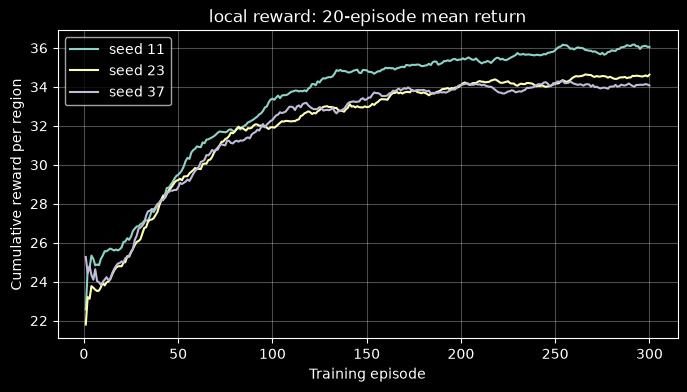

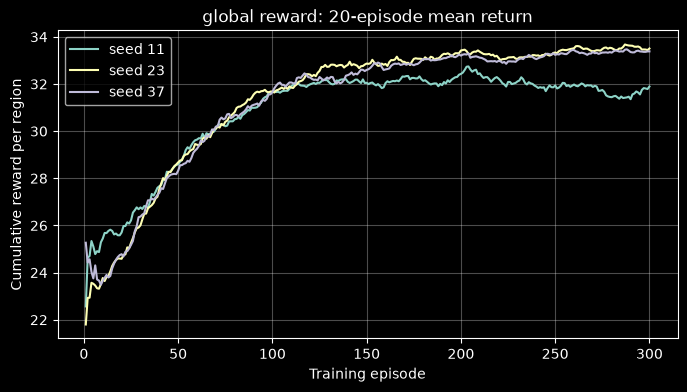

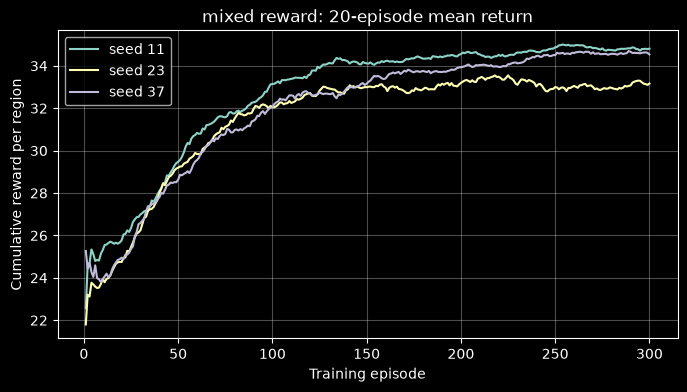

In [13]:
for reward_mode in REWARD_MODES:
    plt.figure(figsize=(8, 4))
    for training_seed in TRAINING_SEEDS:
        selected_rows = training_results[(training_results["reward_mode"] == reward_mode)
                                         & (training_results["training_seed"] == training_seed)]
        running_mean = selected_rows["mean_cumulative_reward_per_region"].rolling(20, min_periods=1).mean()
        plt.plot(selected_rows["episode"], running_mean, label="seed " + str(training_seed))
    plt.title(reward_mode + " reward: 20-episode mean return")
    plt.xlabel("Training episode")
    plt.ylabel("Cumulative reward per region")
    plt.grid(alpha=0.3)
    plt.legend()
    plt.show()

## Matched evaluation

Evaluate each greedy Q policy with the same initial currency, 60% retention, constant development cost, reference pollutant scenarios, and 40-year horizon used for the fixed policies. The environment is deterministic, so matching the starting settings provides a direct policy comparison.

In [14]:
def summarize_policy_run(policy_type, policy_name, trajectory, environment, rewards, action_counts):
    summary = summarize_integrated_episode(policy_name, trajectory, environment)
    gross_income = 0.0
    net_income = 0.0
    edi_total = 0.0
    edi_count = 0
    for info in trajectory:
        for region_result in info["regional_economy"]:
            gross_income += region_result["gross_income"]
            net_income += region_result["net_income"]
            edi_total += region_result["EDI"]
            edi_count += 1
    summary["policy_type"] = policy_type
    summary["gross_income"] = gross_income
    summary["net_income"] = net_income
    summary["average_EDI"] = edi_total / edi_count
    summary["cumulative_reward_all_regions"] = sum(rewards)
    return summary

In [15]:
def record_policy_details(policy_type, policy_name, reward_mode, training_seed, trajectory, action_counts, config):
    for region, counts in enumerate(action_counts):
        for action_name, count in counts.items():
            action_rows.append({"policy_type": policy_type, "policy": policy_name, "reward_mode": reward_mode,
                                "training_seed": training_seed, "region": config.regions[region],
                                "action": action_name, "count": count, "fraction": count / EPISODE_YEARS})
    for step_index, info in enumerate(trajectory, start=1):
        for region, region_result in enumerate(info["regional_economy"]):
            nitrate_mg_l = 1000 * info["stocks"]["Nitrate-N"][region] / config.nitrate["water_volume_m3"]
            lead_total_mg_kg = info["stocks"]["Lead"][region] / config.lead["soil_mass_kg"] * 1e6
            lead_mobile_mg_kg = info["mobile_stocks"]["Lead"][region] / config.lead["soil_mass_kg"] * 1e6
            trajectory_rows.append({"policy_type": policy_type, "policy": policy_name, "reward_mode": reward_mode,
                                    "training_seed": training_seed, "step": step_index, "region": config.regions[region],
                                    "action": region_result["action"], "EDI": region_result["EDI"],
                                    "currency": region_result["currency"], "gross_income": region_result["gross_income"],
                                    "net_income": region_result["net_income"], "development_spending": region_result["development_cost"],
                                    "mitigation_spending": region_result["investment_cost"],
                                    "PM2.5_ug_m3": info["stocks"]["PM2.5"][region], "CO2_ppm": info["stocks"]["CO2"],
                                    "Nitrate-N_mg_L": nitrate_mg_l, "Lead_total_mg_kg": lead_total_mg_kg,
                                    "Lead_mobile_mg_kg": lead_mobile_mg_kg})
    guideline_rows.append(guideline_exceedance_summary(trajectory, config, policy_name))

In [16]:
evaluation_rows = []
action_rows = []
trajectory_rows = []
evaluation_guideline_rows = []
guideline_rows = evaluation_guideline_rows
learned_trajectories = {}

for reward_mode in REWARD_MODES:
    reference_reward = make_reward_function(reward_mode, reference_states)
    for training_seed in TRAINING_SEEDS:
        agents = trained_agents[(reward_mode, training_seed)]
        environment = Study3IntegratedEnvironment(reference_config, starting_currency_multiplier=STARTING_CURRENCY_MULTIPLIER,
                                                  development_cost_shape=REFERENCE_COST_SHAPE,
                                                  income_retention_fraction=REFERENCE_RETENTION)
        rewards, trajectory, action_counts = run_agent_episode(environment, agents, 0, encode_observation,
                                                               decode_actions, reference_reward)
        policy_name = "q_" + reward_mode + "_" + str(training_seed)
        summary = summarize_policy_run("learned", policy_name, trajectory, environment, rewards, action_counts)
        summary["reward_mode"] = reward_mode
        summary["training_seed"] = training_seed
        evaluation_rows.append(summary)
        learned_trajectories[(reward_mode, training_seed)] = trajectory
        record_policy_details("learned", policy_name, reward_mode, training_seed, trajectory, action_counts, reference_config)

for policy_name in FIXED_POLICIES:
    trajectory = fixed_trajectories[policy_name]
    counts = []
    for region in range(number_of_regions):
        region_counts = {}
        for action_name in ACTION_NAMES:
            region_counts[action_name] = 0
        for info in trajectory:
            action_name = info["regional_economy"][region]["action"]
            region_counts[action_name] += 1
        counts.append(region_counts)

    for reward_mode in REWARD_MODES:
        environment = Study3IntegratedEnvironment(reference_config, starting_currency_multiplier=STARTING_CURRENCY_MULTIPLIER,
                                                  development_cost_shape=REFERENCE_COST_SHAPE,
                                                  income_retention_fraction=REFERENCE_RETENTION)
        observations = environment.reset(0)
        rewards = [0.0] * number_of_regions
        while not environment.done:
            actions = choose_fixed_policy_actions(policy_name, environment)
            next_observations, terminated, truncated, info = environment.step(actions)
            step_rewards = rewards_for_mode(reward_mode, observations, next_observations, info, reference_states)
            for region in range(number_of_regions):
                rewards[region] += step_rewards[region]
            observations = next_observations

        summary = summarize_policy_run("fixed", policy_name, trajectory, fixed_environments[policy_name], rewards, counts)
        summary["reward_mode"] = reward_mode
        summary["training_seed"] = None
        evaluation_rows.append(summary)
        record_policy_details("fixed", policy_name, reward_mode, None, trajectory, counts, reference_config)

In [17]:
evaluation_results = pd.DataFrame(evaluation_rows)
action_results = pd.DataFrame(action_rows)
trajectory_results = pd.DataFrame(trajectory_rows)
evaluation_guidelines = pd.DataFrame(evaluation_guideline_rows)

evaluation_results.to_csv(TRAINING_RESULTS_DIRECTORY + "/matched_evaluation.csv", index=False)
action_results.to_csv(TRAINING_RESULTS_DIRECTORY + "/action_frequencies.csv", index=False)
trajectory_results.to_csv(TRAINING_RESULTS_DIRECTORY + "/evaluation_trajectories.csv", index=False)
evaluation_guidelines.to_csv(TRAINING_RESULTS_DIRECTORY + "/guideline_exceedances.csv", index=False)

In [18]:
comparison_columns = ["policy_type", "policy", "reward_mode", "training_seed", "cumulative_reward_all_regions",
                     "final_mean_EDI", "final_min_EDI", "average_EDI", "gross_income", "net_income",
                     "final_mean_currency", "development_spending", "mitigation_spending", "investment_package_purchases",
                     "final_CO2_ppm", "final_mean_PM2.5_ug_m3", "final_mean_nitrate_mg_N_L", "final_mean_lead_total_kg"]
display(evaluation_results[comparison_columns].sort_values(["policy_type", "reward_mode", "training_seed"], na_position="first").round(3))

,policy_type,policy,reward_mode,training_seed,cumulative_reward_all_regions,final_mean_EDI,final_min_EDI,average_EDI,gross_income,net_income,final_mean_currency,development_spending,mitigation_spending,investment_package_purchases,final_CO2_ppm,final_mean_PM2.5_ug_m3,final_mean_nitrate_mg_N_L,final_mean_lead_total_kg
10,fixed,no_development_no_investment,global,NaN,0.000,65.00,55.0,65.000,15896.854,15582.365,2962.355,0.0,0.0,0,525.620,8.563,2.258,16.215
13,fixed,development_only,global,NaN,131.167,98.75,95.0,84.406,16849.575,15853.030,2159.204,3375.0,0.0,0,529.662,8.614,3.209,17.123
16,fixed,prevention_focused,global,NaN,135.950,98.75,95.0,84.406,17755.708,17329.887,1740.733,3375.0,2560.0,32,526.749,8.570,2.568,15.921
19,fixed,cleanup_focused,global,NaN,137.813,98.75,95.0,84.406,17709.473,16827.252,1505.338,3375.0,3200.0,32,529.523,8.614,3.087,12.908
22,fixed,balanced,global,NaN,169.605,98.75,95.0,84.406,18526.238,18216.615,913.742,3375.0,6400.0,32,526.610,8.570,2.445,11.707
9,fixed,no_development_no_investment,local,NaN,0.000,65.00,55.0,65.000,15896.854,15582.365,2962.355,0.0,0.0,0,525.620,8.563,2.258,16.215
12,fixed,development_only,local,NaN,131.167,98.75,95.0,84.406,16849.575,15853.030,2159.204,3375.0,0.0,0,529.662,8.614,3.209,17.123
15,fixed,prevention_focused,local,NaN,135.950,98.75,95.0,84.406,17755.708,17329.887,1740.733,3375.0,2560.0,32,526.749,8.570,2.568,15.921
18,fixed,cleanup_focused,local,NaN,137.813,98.75,95.0,84.406,17709.473,16827.252,1505.338,3375.0,3200.0,32,529.523,8.614,3.087,12.908
21,fixed,balanced,local,NaN,169.605,98.75,95.0,84.406,18526.238,18216.615,913.742,3375.0,6400.0,32,526.610,8.570,2.445,11.707


In [19]:
display(evaluation_guidelines)

,policy,region_years,PM2.5_years_above_9,nitrate_years_above_10,lead_years_above_200
0,q_local_11,160,40,0,0
1,q_local_23,160,40,0,0
2,q_local_37,160,40,0,0
3,q_global_11,160,40,0,0
4,q_global_23,160,40,0,0
5,q_global_37,160,40,0,0
6,q_mixed_11,160,40,0,0
7,q_mixed_23,160,40,0,0
8,q_mixed_37,160,40,0,0
9,no_development_no_investment,160,40,0,0


In [20]:
display(action_results.groupby(["policy_type", "reward_mode", "action"], sort=False)["count"].sum().unstack(fill_value=0))

action                   maintain  develop  prevention  develop_prevention  \
policy_type reward_mode                                                      
learned     local              22      118          10                 116   
            global             57      107          13                  69   
            mixed              30      141          12                 124   
fixed       local             245      459           5                  27   
            global            245      459           5                  27   
            mixed             245      459           5                  27   

action                   cleanup  develop_cleanup  balanced  develop_balanced  
policy_type reward_mode                                                        
learned     local              0              107        13                94  
            global             4               99        29               102  
            mixed              0              102         3                68  
fixed       local              5               27         5                27  
            global             5               27         5                27  
            mixed              5               27         5                27

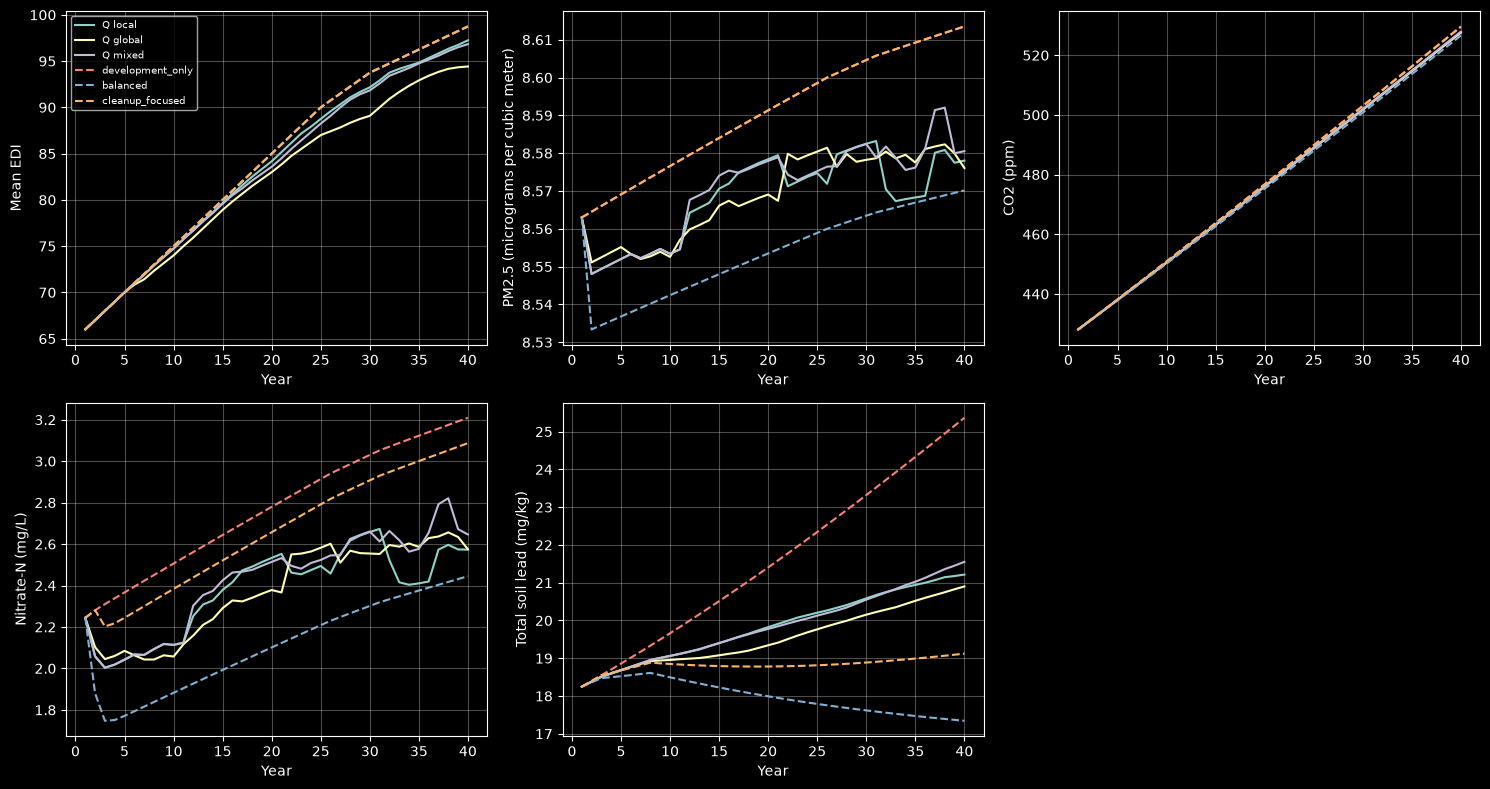

In [21]:
learned_mean_trajectories = trajectory_results[trajectory_results["policy_type"] == "learned"].groupby(
    ["reward_mode", "step"], sort=False)[["EDI", "PM2.5_ug_m3", "CO2_ppm", "Nitrate-N_mg_L", "Lead_total_mg_kg"]].mean().reset_index()

fixed_mean_trajectories = trajectory_results[trajectory_results["policy_type"] == "fixed"].groupby(
    ["policy", "step"], sort=False)[["EDI", "PM2.5_ug_m3", "CO2_ppm", "Nitrate-N_mg_L", "Lead_total_mg_kg"]].mean().reset_index()

figure, axes = plt.subplots(2, 3, figsize=(15, 8))

plot_metrics = [("EDI", "Mean EDI"), ("PM2.5_ug_m3", "PM2.5 (micrograms per cubic meter)"), ("CO2_ppm", "CO2 (ppm)"),
                ("Nitrate-N_mg_L", "Nitrate-N (mg/L)"), ("Lead_total_mg_kg", "Total soil lead (mg/kg)")]

for axis, (metric, label) in zip(axes.flat, plot_metrics):
    for reward_mode in REWARD_MODES:
        rows = learned_mean_trajectories[learned_mean_trajectories["reward_mode"] == reward_mode]
        axis.plot(rows["step"], rows[metric], label="Q " + reward_mode)
    for policy_name in ("development_only", "balanced", "cleanup_focused"):
        rows = fixed_mean_trajectories[fixed_mean_trajectories["policy"] == policy_name]
        axis.plot(rows["step"], rows[metric], linestyle="--", label=policy_name)
    axis.set_ylabel(label)
    axis.set_xlabel("Year")
    axis.grid(alpha=0.3)

axes.flat[5].axis("off")
axes.flat[0].legend(fontsize=7)
plt.tight_layout()
plt.show()

## Regional differences

Compare regional final EDI, currency, and pollutant levels for the three learned reward modes and the fixed policies. This helps identify whether system averages hide a region that consistently lags.

In [22]:
regional_final_rows = []
for evaluation_row in evaluation_rows:
    policy_name = evaluation_row["policy"]

    if evaluation_row["policy_type"] == "learned":
        trajectory = learned_trajectories[(evaluation_row["reward_mode"], evaluation_row["training_seed"])]
    else:
        trajectory = fixed_trajectories[policy_name]

    final_info = trajectory[-1]

    for region, region_result in enumerate(final_info["regional_economy"]):
        nitrate_mg_l = 1000 * final_info["stocks"]["Nitrate-N"][region] / reference_config.nitrate["water_volume_m3"]
        lead_mg_kg = final_info["stocks"]["Lead"][region] / reference_config.lead["soil_mass_kg"] * 1e6
        regional_final_rows.append({"policy_type": evaluation_row["policy_type"], "policy": policy_name,
                                    "reward_mode": evaluation_row["reward_mode"], "training_seed": evaluation_row["training_seed"],
                                    "region": region_result["region"], "final_EDI": region_result["EDI"],
                                    "final_currency": region_result["currency"], "PM2.5_ug_m3": final_info["stocks"]["PM2.5"][region],
                                    "CO2_ppm": final_info["stocks"]["CO2"], "Nitrate-N_mg_L": nitrate_mg_l,
                                    "Lead_total_mg_kg": lead_mg_kg})

regional_final_results = pd.DataFrame(regional_final_rows)
regional_final_results.to_csv(TRAINING_RESULTS_DIRECTORY + "/regional_final_outcomes.csv", index=False)
display(regional_final_results.round(3))

,policy_type,policy,reward_mode,training_seed,region,final_EDI,final_currency,PM2.5_ug_m3,CO2_ppm,Nitrate-N_mg_L,Lead_total_mg_kg
0,learned,q_local_11,local,11.0,Northeast,100.0,1443.897,7.421,527.547,1.702,19.130
1,learned,q_local_11,local,11.0,Midwest,95.0,830.541,8.088,527.547,3.426,20.258
2,learned,q_local_11,local,11.0,South,93.0,1248.444,8.159,527.547,2.971,21.726
3,learned,q_local_11,local,11.0,West,100.0,2114.914,10.604,527.547,1.605,18.888
4,learned,q_local_23,local,23.0,Northeast,100.0,2103.193,7.451,528.299,2.278,19.424
...,...,...,...,...,...,...,...,...,...,...,...
91,fixed,balanced,global,NaN,West,100.0,1386.948,10.605,526.610,1.605,16.056
92,fixed,balanced,mixed,NaN,Northeast,100.0,1150.169,7.421,526.610,1.702,16.692
93,fixed,balanced,mixed,NaN,Midwest,100.0,531.242,8.093,526.610,3.449,19.104
94,fixed,balanced,mixed,NaN,South,95.0,586.610,8.161,526.610,3.024,17.525


## Sensitivity checks

Evaluate the trained Q-tables under 40%, 60%, and 80% income retention; constant and quadratic development costs; low, reference, and high pollutant scenarios; and 0.5x, 1.0x, and 1.5x starting currency. These are evaluation-only changes. The agents are not retrained for these cases.

In [23]:
RETENTION_SENSITIVITY = [0.4, 0.6, 0.8]
COST_SHAPE_SENSITIVITY = ["constant", "quadratic"]
POLLUTANT_SCENARIOS = ["low", "reference", "high"]
CURRENCY_SENSITIVITY = [0.5, 1.0, 1.5]
robustness_rows = []
robustness_trajectory_rows = []

for retention_fraction in RETENTION_SENSITIVITY:
    for cost_shape in COST_SHAPE_SENSITIVITY:
        for pollutant_scenario in POLLUTANT_SCENARIOS:
            scenario_config = EnvironmentConfig(get_parameters(scenarios={
                "pm25": pollutant_scenario,
                "co2": pollutant_scenario,
                "nitrate": pollutant_scenario,
                "lead": pollutant_scenario},
                episode_steps=EPISODE_YEARS))

            for currency_multiplier in CURRENCY_SENSITIVITY:
                scenario_reference = build_no_action_reference(scenario_config, currency_multiplier, retention_fraction)

                for reward_mode in REWARD_MODES:
                    reward_function = make_reward_function(reward_mode, scenario_reference)

                    for training_seed in TRAINING_SEEDS:
                        environment = Study3IntegratedEnvironment(
                            scenario_config,
                            starting_currency_multiplier=currency_multiplier,
                            development_cost_shape=cost_shape,
                            income_retention_fraction=retention_fraction,
                        )

                        agents = trained_agents[(reward_mode, training_seed)]
                        rewards, trajectory, action_counts = run_agent_episode(environment, agents, 0, encode_observation,
                                                                               decode_actions, reward_function)
                        summary = summarize_integrated_episode("q_" + reward_mode, trajectory, environment)
                        summary["policy_type"] = "learned"
                        summary["reward_mode"] = reward_mode
                        summary["training_seed"] = training_seed
                        summary["retention_fraction"] = retention_fraction
                        summary["development_cost_shape"] = cost_shape
                        summary["pollutant_scenario"] = pollutant_scenario
                        summary["starting_currency_multiplier"] = currency_multiplier
                        summary["cumulative_reward_all_regions"] = sum(rewards)
                        summary["guideline_PM2.5_region_years_above_9"] = guideline_exceedance_summary(
                            trajectory, scenario_config, "q_" + reward_mode
                        )["PM2.5_years_above_9"]
                        summary["guideline_nitrate_region_years_above_10"] = guideline_exceedance_summary(
                            trajectory, scenario_config, "q_" + reward_mode
                        )["nitrate_years_above_10"]
                        summary["guideline_lead_region_years_above_200"] = guideline_exceedance_summary(
                            trajectory, scenario_config, "q_" + reward_mode
                        )["lead_years_above_200"]
                        robustness_rows.append(summary)

robustness_results = pd.DataFrame(robustness_rows)
robustness_results.to_csv(TRAINING_RESULTS_DIRECTORY + "/robustness_evaluation.csv", index=False)
print("Evaluation-only cases:", len(robustness_results))

Evaluation-only cases: 486


In [24]:
robustness_summary = robustness_results.groupby(
    ["reward_mode", "retention_fraction", "development_cost_shape", "pollutant_scenario", "starting_currency_multiplier"],
    sort=False,
).agg(
    learned_policies=("training_seed", "count"),
    mean_final_EDI=("final_mean_EDI", "mean"),
    minimum_final_EDI=("final_min_EDI", "min"),
    mean_final_currency=("final_mean_currency", "mean"),
    mean_mitigation_spending=("mitigation_spending", "mean"),
    mean_PM2_5=("final_mean_PM2.5_ug_m3", "mean"),
    mean_CO2=("final_CO2_ppm", "mean"),
    mean_nitrate=("final_mean_nitrate_mg_N_L", "mean"),
    mean_lead_total=("final_mean_lead_total_kg", "mean"),
).reset_index()
display(robustness_summary.round(3))

,reward_mode,retention_fraction,development_cost_shape,pollutant_scenario,starting_currency_multiplier,learned_policies,mean_final_EDI,minimum_final_EDI,mean_final_currency,mean_mitigation_spending,mean_PM2_5,mean_CO2,mean_nitrate,mean_lead_total
0,local,0.4,constant,low,0.5,3,79.083,59.0,1055.590,2706.667,8.567,503.751,2.114,8.340
1,global,0.4,constant,low,0.5,3,76.083,59.0,1201.549,2306.667,8.567,503.613,2.061,8.330
2,mixed,0.4,constant,low,0.5,3,78.750,59.0,1108.171,2513.333,8.567,503.917,2.109,8.305
3,local,0.4,constant,low,1.0,3,91.083,82.0,1178.399,2546.667,8.566,505.421,2.101,8.294
4,global,0.4,constant,low,1.0,3,88.833,78.0,1161.903,2726.667,8.566,505.017,2.086,8.144
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
157,global,0.8,quadratic,high,1.0,3,65.000,55.0,2822.719,0.000,8.563,576.020,2.709,56.123
158,mixed,0.8,quadratic,high,1.0,3,65.000,55.0,2822.719,0.000,8.563,576.020,2.709,56.123
159,local,0.8,quadratic,high,1.5,3,65.000,55.0,3135.219,0.000,8.563,576.020,2.709,56.123
160,global,0.8,quadratic,high,1.5,3,65.000,55.0,3135.219,0.000,8.563,576.020,2.709,56.123


In [25]:
coverage_rows = []
for pollutant_scenario in ["reference", "high"]:
    coverage_config = EnvironmentConfig(get_parameters(scenarios={
        "pm25": pollutant_scenario,
        "co2": pollutant_scenario,
        "nitrate": pollutant_scenario,
        "lead": pollutant_scenario},
        episode_steps=EPISODE_YEARS))

    coverage_environment = Study3IntegratedEnvironment(coverage_config, income_retention_fraction=REFERENCE_RETENTION)
    initial_observations = coverage_environment.reset(0)

    for reward_mode in REWARD_MODES:
        agents = trained_agents[(reward_mode, TRAINING_SEEDS[0])]
        unseen_regions = 0
        for region, observation in enumerate(initial_observations):
            if encode_observation(observation) not in agents[region].q_values:
                unseen_regions += 1
        coverage_rows.append({"pollutant_scenario": pollutant_scenario, "reward_mode": reward_mode,
                              "regions_with_unseen_initial_state": unseen_regions})
coverage_summary = pd.DataFrame(coverage_rows)
display(coverage_summary)

,pollutant_scenario,reward_mode,regions_with_unseen_initial_state
0,reference,local,0
1,reference,global,0
2,reference,mixed,0
3,high,local,4
4,high,global,4
5,high,mixed,4


## Findings and next steps

- Training returns increased in all three reward modes, but three seeds and 300 episodes are an initial pilot, not evidence of convergence.
- On matched reference conditions, mean final EDI was 97.25 for local, 94.42 for global, and 96.83 for mixed rewards. The balanced fixed policy reached 98.75. Learned policies did not outperform the strongest fixed baseline.
- Mean mitigation spending was 3,360 for local, 3,433 for global, and 2,973 for mixed policies, compared with 6,400 for the balanced baseline. The learned policies ended with higher mean pollution than balanced: CO2 averaged 527.6 to 527.9 ppm, nitrate 2.57 to 2.65 mg N/L, and total lead 14.1 to 14.6 kg; balanced ended at 526.6 ppm, 2.45 mg N/L, and 11.71 kg. PM2.5 was similar at about 8.57 to 8.58 micrograms per cubic meter.
- Reward modes produced different action mixes. Local policies favored development with cleanup or prevention; global policies used more maintenance and balanced actions; mixed policies developed frequently and spent less on mitigation. Results vary across training seeds.
- The aggregate fixed-policy reward is equal across local, global, and mixed modes by construction, so policy outcomes and action choices are more useful for comparing the reward structures. The reward counts both development progress and pollution relative to the no-action path. Environmental damage also reduces future income and can constrain EDI growth. This is an intentional two-objective tradeoff, but it means environmental harm can affect both reward components through distinct pathways.
- In the high-pollution sensitivity cases, all four initial states were unseen in the trained Q-tables. For unseen states, greedy tie-breaking selects `maintain`; the resulting no-investment behavior is a coverage limitation, not evidence that training learned to ignore pollution. Treat high-scenario results as out-of-distribution diagnostics.
- The reference-condition guideline comparison recorded 40 PM2.5 region-years above 9 micrograms per cubic meter, with no nitrate or lead comparison exceedances. These counts are screening comparisons and do not terminate episodes.

The environment and tabular pipeline now run reproducibly, and the first policies respond to their reward signals. Before extending training, improve state coverage for changed pollution conditions and inspect whether the pollution reward weight gives the intended balance against development. Keep the environment equations and reference parameters fixed during that work.
